# C3 riêng của Nhật Huy — kiểm hồ sơ huấn luyện và metric lịch sử
    **Giới hạn đã xác nhận:** workspace có log, metadata, confusion counts và bảng kết quả,
    nhưng **thiếu ba bundle checkpoint/scores C3 riêng**. Notebook này thực sự chạy các
    phép kiểm hồ sơ và tính lại bảy metric từ TP/FP/FN/TN; **không suy luận model C3 riêng**.
    Không thay bundle đó bằng DistilBERT của benchmark chung. C3 chung đã được chạy
    lại đủ ba seed trong notebook 04 và có protocol khác.

    Nghiên cứu riêng này chỉ dùng train/validation; các số dưới không phải test.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/notebook_support.py').is_file())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from src.notebook_support import artifacts_root
from src.datasets.goemotions import load_goemotions, multi_hot, sha256, REVISION
from src.evaluation.protocols import read_json
from src.evaluation.metrics import evaluate_multilabel
from src.models.transformer import METRIC_NAMES
ARTIFACTS = artifacts_root()
pd.set_option('display.max_columns', 18)
pd.set_option('display.max_colwidth', 100)
print('Python:', sys.version.split()[0])
print('Dataset revision:', REVISION)
print('Artifacts:', ARTIFACTS.name)

REPORT = ARTIFACTS/'reports/c3_distilbert/full'
protocol = read_json(REPORT/'protocol.json')
frames, names, manifest = load_goemotions(ARTIFACTS, write_metadata=False, splits=('train','validation'))
print('Chế độ lần chạy: kiểm hồ sơ lịch sử và confusion counts, không nạp checkpoint riêng.')

Python: 3.13.9
Dataset revision: add492243ff905527e67aeb8b80c082af02207c3
Artifacts: goemotions-multilabel-classification


Chế độ lần chạy: kiểm hồ sơ lịch sử và confusion counts, không nạp checkpoint riêng.


## 1. Cấu hình, dataset và phạm vi đã khóa

In [2]:
config = protocol['config']
assert config == read_json(ROOT/'configs/distilbert_full.json')
assert protocol['seeds'] == [42,123,2026] and not protocol['test_used']
assert len(frames['train']) == 43410 and len(frames['validation']) == 5426
assert not (set(frames['train'].id) & set(frames['validation'].id))
display(pd.Series(config))
display(pd.DataFrame([dict(split=s, rows=len(df), unique_ids=df.id.nunique()) for s,df in frames.items()]))

mode                                                               full
model_id                             distilbert/distilbert-base-uncased
revision                       12040accade4e8a0f71eabdb258fecc2e7e948be
seed                                                                 42
subset_seed                                                        2026
train_limit                                                        None
validation_limit                                                   None
epochs                                                                3
max_length                                                          128
batch_size                                                           16
gradient_accumulation_steps                                           1
eval_batch_size                                                      16
learning_rate                                                   0.00002
weight_decay                                                    

,split,rows,unique_ids
0,train,43410,43410
1,validation,5426,5426


## 2. Kiểm rõ tệp checkpoint/scores còn thiếu

In [3]:
availability = []
for seed in protocol['seeds']:
    run = ARTIFACTS/f'data/processed/c3_distilbert/full/seed_{seed}'
    availability.append(dict(seed=seed, checkpoint_available=(run/'best/model.safetensors').is_file(),
        scores_available=(run/'validation_scores.npz').is_file(),
        historical_metadata_available=(REPORT/f'run_seed_{seed}.json').is_file()))
display(pd.DataFrame(availability))
print('Không chứng nhận reload, loss forward hoặc suy luận C3 riêng mới khi bundle chưa có.')

,seed,checkpoint_available,scores_available,historical_metadata_available
0,42,False,False,True
1,123,False,False,True
2,2026,False,False,True


Không chứng nhận reload, loss forward hoặc suy luận C3 riêng mới khi bundle chưa có.


## 3. Metadata huấn luyện đã bàn giao và best epoch

In [4]:
history = pd.read_csv(REPORT/'history_all_seeds.csv')
receipts = []
for seed in protocol['seeds']:
    meta = read_json(REPORT/f'run_seed_{seed}.json')
    rows = history[history.seed == seed]
    best = rows.sort_values(['validation_macro_f1','epoch'], ascending=[False,True]).iloc[0]
    assert meta['best_epoch'] == int(best.epoch) and not meta['test_used']
    assert meta['n_train'] == 43410 and meta['n_validation'] == 5426
    receipts.append(dict(seed=seed, best_epoch=meta['best_epoch'], n_train=meta['n_train'],
        n_validation=meta['n_validation'], gpu=meta['environment']['gpu'],
        model_sha256=meta['artifact_sha256']['best/model.safetensors']))
display(pd.DataFrame(receipts))

,seed,best_epoch,n_train,n_validation,gpu,model_sha256
0,42,3,43410,5426,NVIDIA GeForce RTX 3050 Laptop GPU,b695fd208dc3d7e28a051993c09f1d5018be8be4fe2b694b340f1877bf2ed993
1,123,3,43410,5426,NVIDIA GeForce RTX 3050 Laptop GPU,ca73ce76dd7186e52b2d9fc77b04b25bda2df0eb1a4061e900c0e171bc9a9e3a
2,2026,3,43410,5426,NVIDIA GeForce RTX 3050 Laptop GPU,252675c898007bb2d3da8fe6d182554a171ed0c2f8a48ab30d9002e4a0813b4e


## 4. Lịch sử học và tài nguyên — đọc từ log cũ

,seed,epoch,train_loss,validation_macro_f1,validation_micro_f1,epoch_train_and_eval_seconds
0,42,1,0.163071,0.263345,0.512500,491.594978
1,42,2,0.085828,0.372952,0.554580,454.450361
2,42,3,0.075794,0.403256,0.568935,464.302000
3,123,1,0.162743,0.269107,0.507444,452.904308
4,123,2,0.086294,0.386296,0.564292,466.958364
5,123,3,0.076224,0.411325,0.576176,457.801856
6,2026,1,0.161807,0.243192,0.518810,648.382768
7,2026,2,0.086021,0.382368,0.563892,642.638549
8,2026,3,0.075922,0.403670,0.573720,664.372091


,seed,skipped_amp_steps,best_epoch,optimizer_steps,effective_batch_size,trainable_parameters,fit_and_validation_seconds,peak_cuda_allocated_mib,peak_cuda_reserved_mib,reload_max_abs_score_diff
0,42,1,3,8141,16,66975004,1411.581204,1363.134766,1476.0,0.0
1,123,1,3,8141,16,66975004,1383.677994,1363.791016,1476.0,0.0
2,2026,1,3,8141,16,66975004,1957.309895,1363.791016,1476.0,0.0


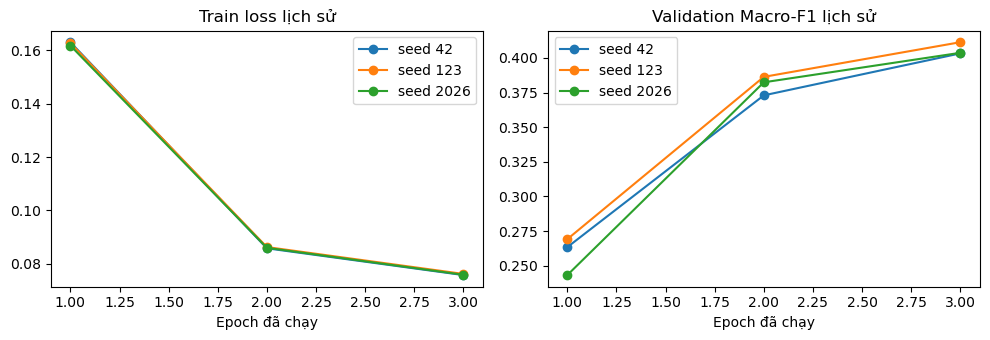

Log seed
42
:
epoch=3, validation Macro-F1@0.5=0.40326
PASS: full complete, best epoch=3, reload diff=0
D:\Nam_3\HK1\NLP\LT\goemotions-multilabel-classification\data\processed\c3_distilbert\full\seed_42
Log seed
123
:
epoch=3, validation Macro-F1@0.5=0.41133
PASS: full complete, best epoch=3, reload diff=0
D:\Nam_3\HK1\NLP\LT\goemotions-multilabel-classification\data\processed\c3_distilbert\full\seed_123
Log seed
2026
:
epoch=3, validation Macro-F1@0.5=0.40367
PASS: full complete, best epoch=3, reload diff=0
D:\Nam_3\HK1\NLP\LT\goemotions-multilabel-classification\data\processed\c3_distilbert\full\seed_2026


In [5]:
import matplotlib.pyplot as plt
display(history)
display(pd.read_csv(REPORT/'resources_all_seeds.csv'))
fig, axes = plt.subplots(1,2,figsize=(10,3.5))
for seed, group in history.groupby('seed'):
    axes[0].plot(group.epoch, group.train_loss, marker='o', label=f'seed {seed}')
    axes[1].plot(group.epoch, group.validation_macro_f1, marker='o', label=f'seed {seed}')
axes[0].set_title('Train loss lịch sử'); axes[1].set_title('Validation Macro-F1 lịch sử')
for ax in axes: ax.set_xlabel('Epoch đã chạy'); ax.legend()
plt.tight_layout(); plt.show(); plt.close()
for seed in protocol['seeds']:
    print('Log seed',seed,':',*(REPORT/f'train_seed_{seed}.log').read_text(encoding='utf-8').splitlines()[-3:],sep='\n')

## 5. Tính lại đủ bảy metric từ confusion counts thật
    TP/FP/FN/TN của đủ 28 nhãn được giữ trong CSV bàn giao. Các phép tính này không
    cần weights; chúng kiểm tính nhất quán của số liệu lịch sử, không kiểm lại scores
    hoặc checkpoint bị thiếu. Số mẫu mỗi nhãn phải đúng 5.426.

In [6]:
from src.notebook_support import metrics_from_confusion
counts = pd.read_csv(REPORT/'per_label_all_seeds.csv')
reported = pd.read_csv(REPORT/'threshold_comparison_runs.csv')
support = multi_hot(frames['train'].labels.tolist()).sum(axis=0)
rows, differences = [], []
for (seed,mode), group in counts.groupby(['seed','mode'], sort=True):
    group = group.sort_values('label_id')
    assert group.label.tolist() == names and group.label_id.tolist() == list(range(28))
    np.testing.assert_array_equal(group.train_support, support)
    metric = metrics_from_confusion(group, 5426)
    expected = reported[(reported.seed == seed) & (reported['mode'] == mode)].iloc[0]
    filename = ('fixed' if mode == 'fixed_0.5' else 'tuned')
    original = read_json(REPORT/f'metrics_{filename}_seed_{seed}.json')
    for key in METRIC_NAMES:
        differences.extend([abs(metric[key]-expected[key]),abs(metric[key]-original[key])])
    rows.append(dict(seed=seed, mode=mode, **metric))
assert len(rows) == 6 and max(differences) <= 1e-12
recalculated = pd.DataFrame(rows)
display(recalculated)
print('PASS: 6 dòng validation; sai lệch từ confusion counts:',max(differences))

,seed,mode,macro_precision,macro_recall,macro_f1,micro_precision,micro_recall,micro_f1,hamming_loss
0,42,fixed_0.5,0.572258,0.343198,0.403256,0.709006,0.475078,0.568935,0.030231
1,42,per_label_tuned_on_validation,0.510012,0.542656,0.512029,0.545175,0.667712,0.600254,0.037347
2,123,fixed_0.5,0.576251,0.351337,0.411325,0.712373,0.483699,0.576176,0.029883
3,123,per_label_tuned_on_validation,0.545091,0.518848,0.509678,0.558971,0.664107,0.607020,0.036109
4,2026,fixed_0.5,0.570269,0.344497,0.403670,0.708266,0.482132,0.573720,0.030087
5,2026,per_label_tuned_on_validation,0.518457,0.524693,0.510227,0.553321,0.655486,0.600086,0.036688


PASS: 6 dòng validation; sai lệch từ confusion counts: 8.326672684688674e-17


## 6. Mean và sample std từ đủ ba seed của nghiên cứu riêng

In [7]:
summary = recalculated.groupby('mode')[list(METRIC_NAMES)].agg(['mean','std'])
display(summary)
saved = pd.read_csv(REPORT/'threshold_comparison_mean_std.csv')
for _,row in saved.iterrows():
    assert abs(summary.loc[row['mode'],(row['metric'],'mean')]-row['mean']) <= 1e-12
    assert abs(summary.loc[row['mode'],(row['metric'],'std')]-row['sample_std']) <= 1e-12
print('PASS: mean và sample std khớp CSV lịch sử. Không gộp các run này vào C3 chung.')

macro_f1            micro_f1            \
                                   mean       std      mean       std   
mode                                                                    
fixed_0.5                      0.406084  0.004544  0.572944  0.003683   
per_label_tuned_on_validation  0.510645  0.001230  0.602453  0.003956   

                              macro_precision           macro_recall  \
                                         mean       std         mean   
mode                                                                   
fixed_0.5                            0.572926  0.003046     0.346344   
per_label_tuned_on_validation        0.524520  0.018308     0.528732   

                                        micro_precision            \
                                    std            mean       std   
mode                                                                
fixed_0.5                      0.004372        0.709882  0.002189   
per_label_tuned_on_validation  0.012407        0.552489  0.006935   

                              micro_recall           hamming_loss            
                                      mean       std         mean       std  
mode                                                                         
fixed_0.5                         0.480303  0.004592     0.030067  0.000175  
per_label_tuned_on_validation     0.662435  0.006282     0.036715  0.000619

PASS: mean và sample std khớp CSV lịch sử. Không gộp các run này vào C3 chung.


## 7. Ngưỡng riêng và nhãn hiếm — validation đã dùng chọn ngưỡng

In [8]:
threshold_rows=[]
for seed in protocol['seeds']:
    saved=read_json(REPORT/f'thresholds_seed_{seed}.json')
    assert saved['label_names']==names and not saved['test_used']
    for label,value in zip(names,saved['thresholds']):
        threshold_rows.append(dict(seed=seed,label=label,threshold=value))
display(pd.DataFrame(threshold_rows).pivot(index='label',columns='seed',values='threshold').reindex(names))
display(pd.read_csv(REPORT/'rare_labels_mean_std.csv'))
print('Tuned-validation không phải test độc lập; không chứng minh cải thiện trên test.')

seed,42,123,2026
label,,,
admiration,0.45,0.40,0.40
amusement,0.35,0.25,0.45
anger,0.30,0.35,0.30
annoyance,0.20,0.20,0.15
approval,0.15,0.20,0.20
caring,0.20,0.35,0.20
confusion,0.20,0.25,0.25
curiosity,0.15,0.25,0.20
desire,0.35,0.15,0.20


,label,mode,train_support,validation_support,f1_mean,f1_std,precision_mean,recall_mean
0,embarrassment,fixed_0.5,303,35,0.334511,0.056319,0.714646,0.219048
1,grief,fixed_0.5,77,13,0.000000,0.000000,0.000000,0.000000
2,nervousness,fixed_0.5,164,21,0.000000,0.000000,0.000000,0.000000
3,pride,fixed_0.5,111,15,0.000000,0.000000,0.000000,0.000000
4,relief,fixed_0.5,153,18,0.000000,0.000000,0.000000,0.000000
5,embarrassment,per_label_tuned_on_validation,303,35,0.546730,0.014079,0.705758,0.447619
6,grief,per_label_tuned_on_validation,77,13,0.000000,0.000000,0.000000,0.000000
7,nervousness,per_label_tuned_on_validation,164,21,0.385569,0.013978,0.579545,0.349206
8,pride,per_label_tuned_on_validation,111,15,0.594517,0.063819,0.915344,0.444444
9,relief,per_label_tuned_on_validation,153,18,0.048780,0.084490,0.043478,0.055556


Tuned-validation không phải test độc lập; không chứng minh cải thiện trên test.


## 8. Kiểm nguyên văn, ID và nhãn thật của ví dụ lỗi đã bàn giao

In [9]:
examples=read_json(REPORT/'error_examples.json')
by_id=frames['validation'].set_index('id')
for example in examples:
    row=by_id.loc[example['id']]
    assert row.text==example['text'] and [names[j] for j in row.labels]==example['true_labels']
display(pd.DataFrame([{k:v for k,v in e.items() if k!='scores'} for e in examples]).groupby('group',sort=False).head(3))
display(pd.read_csv(REPORT/'error_group_counts.csv'))
print('PASS:',len(examples),'ví dụ có ID/văn bản/nhãn thật khớp snapshot validation.')

,group,seed,id,text,true_labels,predicted_labels,missed_labels,extra_labels,threshold
0,FN_va_FP_cung_cau,123,eczg2g7,I'm in the Central Time Zone in the US so I have some time to go. But Happy New Year to you man!,[neutral],[joy],[neutral],[joy],0.5
1,FN_va_FP_cung_cau,123,eczh1pf,[NAME] speed!,[admiration],[neutral],[admiration],[neutral],0.5
2,FN_va_FP_cung_cau,123,eczj0in,Kinda let down tbh,"[annoyance, disappointment]",[neutral],"[annoyance, disappointment]",[neutral],0.5
12,thieu_mot_phan_nhan_that,123,eczdu8p,"Oooh yes, great idea. Too bad there aren't any other duplicate names","[admiration, disapproval]",[admiration],[disapproval],[],0.5
13,thieu_mot_phan_nhan_that,123,eczfzzk,I drove off 170 onto 40 and was surprised by the lack of brakelights.... keep it closed haha,"[amusement, surprise]",[surprise],[amusement],[],0.5
14,thieu_mot_phan_nhan_that,123,eczhjuj,"it sounds like you're setting up for a good 2019 keep the boundaries going, and I hope the surg...","[approval, optimism]",[optimism],[approval],[],0.5
24,sai_nhan_hiem_hoac_neutral,123,eczdhfb,"You still look cranky, goodnight.",[neutral],[],[neutral],[],0.5
25,sai_nhan_hiem_hoac_neutral,123,eczg2g7,I'm in the Central Time Zone in the US so I have some time to go. But Happy New Year to you man!,[neutral],[joy],[neutral],[joy],0.5
26,sai_nhan_hiem_hoac_neutral,123,eczh1pf,[NAME] speed!,[admiration],[neutral],[admiration],[neutral],0.5


,seed,group,n_samples,n_validation,note
0,42,FN_va_FP_cung_cau,1167,5426,Groups may overlap; counts are not additive
1,42,thieu_mot_phan_nhan_that,458,5426,Groups may overlap; counts are not additive
2,42,sai_nhan_hiem_hoac_neutral,1255,5426,Groups may overlap; counts are not additive
3,123,FN_va_FP_cung_cau,1168,5426,Groups may overlap; counts are not additive
4,123,thieu_mot_phan_nhan_that,480,5426,Groups may overlap; counts are not additive
5,123,sai_nhan_hiem_hoac_neutral,1218,5426,Groups may overlap; counts are not additive
6,2026,FN_va_FP_cung_cau,1184,5426,Groups may overlap; counts are not additive
7,2026,thieu_mot_phan_nhan_that,463,5426,Groups may overlap; counts are not additive
8,2026,sai_nhan_hiem_hoac_neutral,1224,5426,Groups may overlap; counts are not additive


PASS: 36 ví dụ có ID/văn bản/nhãn thật khớp snapshot validation.


## 9. Hồ sơ kiểm demo cũ và bước để khôi phục suy luận
    File verification dưới được tạo trên máy chạy C3 riêng trước đây. Ngày kiểm và
    kết quả đó được giữ nguyên; không diễn giải thành lượt kiểm UI mới hôm nay.
    Muốn chạy model C3 riêng cần nhận lại `best/`, `run.json`, scores/ID và các hash.
    Sau khi có bundle, dùng `scripts.distilbert.verify_distilbert`; demo cuối nhóm
    hiện dùng BERT seed 123 tại `app.py`.

In [10]:
receipt=read_json(REPORT/'verification.json')
display(pd.Series({k:receipt[k] for k in ('checked_at_utc','status','run','test_used')}))
display(pd.DataFrame(receipt['checks'].items(),columns=['Kiểm lịch sử','Kết quả đã ghi']))
print('Hoàn tất kiểm hồ sơ C3 riêng; checkpoint mới nạp: 0; suy luận mới: 0.')
print('C3 CHUNG: xem notebook 04 với ba checkpoint đã suy luận test thật.')

checked_at_utc              2026-10-08T13:46:49.140609+00:00
status                                                passed
run               data/processed/c3_distilbert/full/seed_123
test_used                                              False
dtype: object

,Kiểm lịch sử,Kết quả đã ghi
0,artifact_sha256_and_mapping,passed
1,sample_ids_and_npz_alignment,passed
2,validation_metrics_recomputed,passed
3,checkpoint_reload_during_training,passed
4,cli_shared_inference_scores_and_labels,passed
5,streamlit_widget_prediction_scores_and_labels,passed
6,streamlit_empty_text_handling,passed
7,streamlit_long_text_truncation_notice,passed


Hoàn tất kiểm hồ sơ C3 riêng; checkpoint mới nạp: 0; suy luận mới: 0.
C3 CHUNG: xem notebook 04 với ba checkpoint đã suy luận test thật.
